=== TUGAS UTS - Marselina Londa - RS 35 ===
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Theta: [28.05748153  9.23660641]
MSE: 49.756024928644194


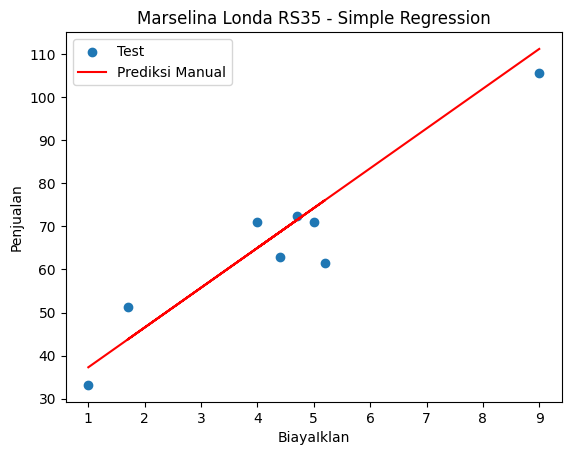

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Accuracy: 1.0
[[4 0]
 [0 8]]


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nama: Marselina Londa
# NIM: ...35
# Kelas: Reg B / Reg C (pilih)
# random_state = 35 (2 digit terakhir NIM)

def train_test_split_manual(X, y, test_size=0.2, random_state=35):
    np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_n = int(len(X)*test_size)
    test_idx, train_idx = indices[:test_n], indices[test_n:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegressionManual:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return X_b.dot(self.theta)

class LinearRegressionGD:
    def fit(self, X, y, lr=0.001, epochs=2000):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.zeros(X_b.shape[1])
        for _ in range(epochs):
            grad = (2/len(X_b))*X_b.T.dot(X_b.dot(self.theta)-y)
            self.theta -= lr*grad
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return X_b.dot(self.theta)

class LogisticRegressionManual:
    def sigmoid(self,z): return 1/(1+np.exp(-z))
    def fit(self,X,y,lr=0.01,epochs=1000):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        self.theta = np.zeros(X_b.shape[1])
        for _ in range(epochs):
            h = self.sigmoid(X_b.dot(self.theta))
            grad = (1/len(X_b))*X_b.T.dot(h-y)
            self.theta -= lr*grad
    def predict(self,X):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        return (self.sigmoid(X_b.dot(self.theta))>=0.5).astype(int)

def mse_manual(y_true,y_pred): return np.mean((y_true-y_pred)**2)
def accuracy_manual(y_true,y_pred): return np.mean(y_true==y_pred)
def confusion_matrix_manual(y_true,y_pred):
    tp=np.sum((y_true==1)&(y_pred==1)); tn=np.sum((y_true==0)&(y_pred==0))
    fp=np.sum((y_true==0)&(y_pred==1)); fn=np.sum((y_true==1)&(y_pred==0))
    return np.array([[tn,fp],[fn,tp]])

# ========== SOAL 1: REGRESI ==========
print("=== TUGAS UTS - Marselina Londa - RS 35 ===")
df=pd.read_csv('Ads_Data.csv')
print(df.head())
X=df[['BiayaIklan']].values; y=df['Penjualan'].values

X_train,X_test,y_train,y_test=train_test_split_manual(X,y,random_state=35)

model=LinearRegressionManual()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

print(f"Theta: {model.theta}")
print(f"MSE: {mse_manual(y_test,y_pred)}")

plt.scatter(X_test,y_test,label='Test')
plt.plot(X_test,y_pred,color='red',label='Prediksi Manual')
plt.title('Marselina Londa RS35 - Simple Regression')
plt.xlabel('BiayaIklan'); plt.ylabel('Penjualan'); plt.legend(); plt.show()

# ========== SOAL 2: KLASIFIKASI ==========
df2=pd.read_csv('Email_Data.csv')
print(df2.head())
X2=df2.drop(columns=[df2.columns[-1]]).values
y2=df2[df2.columns[-1]].values

X2_train,X2_test,y2_train,y2_test=train_test_split_manual(X2,y2,random_state=35)

model2=LogisticRegressionManual()
model2.fit(X2_train,y2_train)
y2_pred=model2.predict(X2_test)

print(f"Accuracy: {accuracy_manual(y2_test,y2_pred)}")
print(confusion_matrix_manual(y2_test,y2_pred))